In [55]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, roc_auc_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
import xgboost as xgb
import shap
import warnings
warnings.filterwarnings('ignore')
shap.initjs()

In [56]:
class DataLoader():
    def __init__(self):
        self.data = None

    def load_dataset(self, path="data/healthcare-dataset-stroke-data.csv"):
        self.data = pd.read_csv(path)

    def preprocess_data(self):
        # 🔥 Remove underage rows (age < 18)
        self.data = self.data[self.data["age"] >= 18]

        # 🔥 Drop rows with missing BMI
        self.data = self.data.dropna(subset=["bmi"])

        # One-hot encode categorical columns
        categorical_cols = [
            "gender",
            "ever_married",
            "work_type",
            "Residence_type",
            "smoking_status"
        ]

        encoded = pd.get_dummies(
            self.data[categorical_cols],
            prefix=categorical_cols,
            dtype=int
        )

        # Add encoded columns, drop originals
        self.data = pd.concat([encoded, self.data], axis=1)
        self.data.drop(categorical_cols, axis=1, inplace=True)

        # Drop useless ID column
        self.data.drop(["id"], axis=1, inplace=True)

        # Reset index after dropping rows
        self.data.reset_index(drop=True, inplace=True)

    def get_data_split(self):
        X = self.data.iloc[:, :-1]
        y = self.data.iloc[:, -1]
        return train_test_split(X, y, test_size=0.20, random_state=2021)

    def oversample(self, X_train, y_train):
        oversample = RandomOverSampler(sampling_strategy='minority')
        
        # Convert to numpy for SMOTE
        x_np = X_train.to_numpy()
        y_np = y_train.to_numpy()

        x_np, y_np = oversample.fit_resample(x_np, y_np)

        # Convert back to pandas
        x_over = pd.DataFrame(x_np, columns=X_train.columns)
        y_over = pd.Series(y_np, name=y_train.name)
        return x_over, y_over



#   Task 1: EDA

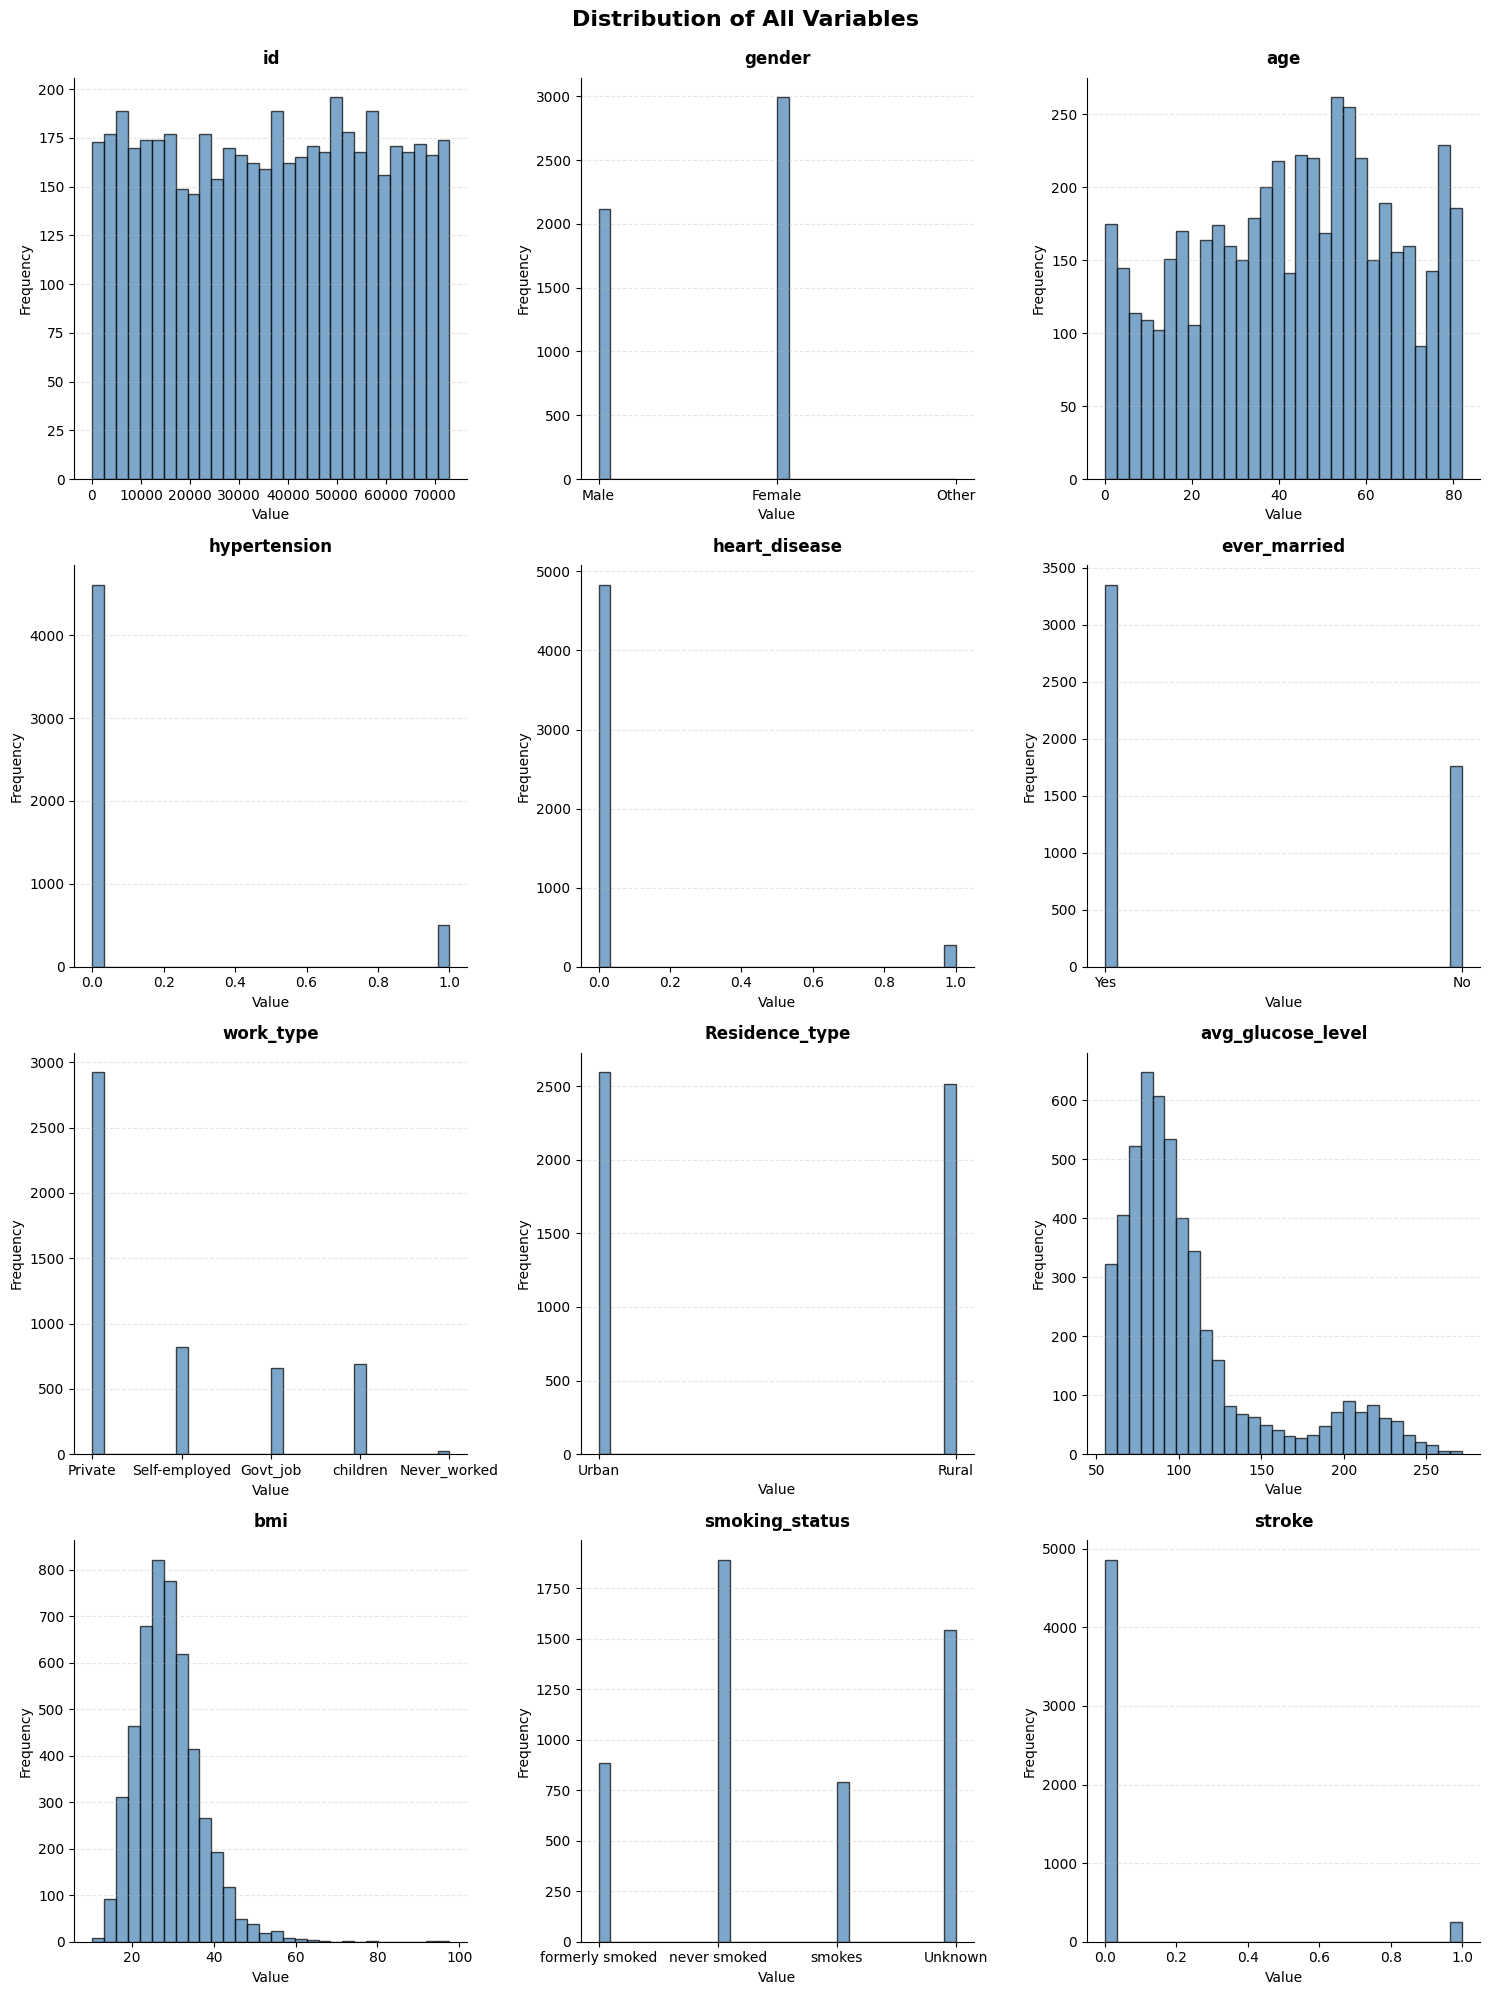

In [57]:
data_loader = DataLoader()
data_loader.load_dataset()
data = data_loader.data

# Get columns from the dataloader's data
columns = data_loader.data.columns
data = data_loader.data

# Get number of columns and calculate grid dimensions
n_cols = len(columns)
n_rows = int(np.ceil(n_cols / 3))  # 3 columns per row
n_plot_cols = min(n_cols, 3)

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_plot_cols, figsize=(15, 5 * n_rows))
fig.suptitle('Distribution of All Variables', fontsize=16, fontweight='bold', y=0.995)

# Flatten axes array for easier iteration
if n_cols == 1:
    axes = [axes]
elif n_rows == 1:
    axes = axes.flatten()
else:
    axes = axes.flatten()

# Plot histograms
for idx, col in enumerate(columns):
    ax = axes[idx]
    
    # Create histogram with better styling
    ax.hist(data[col].dropna(), bins=30, color='steelblue', 
            edgecolor='black', alpha=0.7)
    
    # Styling
    ax.set_title(col, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Value', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide any unused subplots
for idx in range(n_cols, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

# Task 2: Train a Random Forest Model And Create A SHAP Explainer

In [58]:
# Initialize DataLoader
loader = DataLoader()
loader.load_dataset("data/healthcare-dataset-stroke-data.csv")

print(f"Dataset shape: {loader.data.shape}")
print(f"\nFirst few rows:")
print(loader.data.head())

print(f"\nTarget distribution (before preprocessing):")
print(loader.data['stroke'].value_counts())

# Preprocess data
loader.preprocess_data()

print(f"\nDataset shape after preprocessing: {loader.data.shape}")
print(f"\nFeature columns after one-hot encoding:")
print(list(loader.data.columns[:-1]))

# Split data
X_train, X_test, y_train, y_test = loader.get_data_split()

print(f"\nOriginal Training set size: {X_train.shape}")
print(f"Original Test set size: {X_test.shape}")
print(f"Training set class distribution:\n{y_train.value_counts()}")

# Oversample training data
X_train_over, y_train_over = loader.oversample(X_train, y_train)

print(f"\nOversampled Training set size: {X_train_over.shape}")
print(f"Oversampled class distribution:\n{y_train_over.value_counts()}")

Dataset shape: (5110, 12)

First few rows:
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  

Target distr

In [59]:
# Train Random Forest on oversampled data
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

rf_model.fit(X_train_over, y_train_over)

# Predictions on original test set
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("\nRandom Forest Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Random Forest Performance:
Accuracy: 0.8699
F1 Score: 0.2639
ROC-AUC Score: 0.7969

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.90      0.93       770
           1       0.19      0.42      0.26        45

    accuracy                           0.87       815
   macro avg       0.58      0.66      0.60       815
weighted avg       0.92      0.87      0.89       815



In [60]:
#Create SHAP Explainer for Random Forest
print("\nCreating SHAP TreeExplainer for Random Forest...")
explainer_rf = shap.TreeExplainer(rf_model)
shap_values_rf_raw = explainer_rf.shap_values(X_test)


Creating SHAP TreeExplainer for Random Forest...


In [61]:
# For binary classification, get values for positive class (stroke=1)
if isinstance(shap_values_rf_raw, list):
    shap_values_rf = shap_values_rf_raw[1]
else:
    shap_values_rf = shap_values_rf_raw

print(f"✓ SHAP values computed! Shape: {shap_values_rf.shape}")

✓ SHAP values computed! Shape: (815, 20, 2)


# Task 3: Create Force Plot

In [62]:
# Select interesting cases for explanation
high_risk_idx = np.argmax(y_pred_proba_rf)
low_risk_idx = np.argmin(y_pred_proba_rf)

# Get a stroke case if exists
stroke_cases = np.where(y_test == 1)[0]
if len(stroke_cases) > 0:
    stroke_idx = stroke_cases[0]
else:
    stroke_idx = high_risk_idx

print(f"\nSelected cases for local explanation:")
print(f"High risk case (index {high_risk_idx}): Predicted probability = {y_pred_proba_rf[high_risk_idx]:.4f}")
print(f"Low risk case (index {low_risk_idx}): Predicted probability = {y_pred_proba_rf[low_risk_idx]:.4f}")
print(f"Stroke case (index {stroke_idx}): Predicted probability = {y_pred_proba_rf[stroke_idx]:.4f}, Actual: {y_test.iloc[stroke_idx]}")


Selected cases for local explanation:
High risk case (index 484): Predicted probability = 0.8340
Low risk case (index 66): Predicted probability = 0.0000
Stroke case (index 2): Predicted probability = 0.0893, Actual: 1


In [63]:
shap_values_pos = shap_values_rf[:, :, 1]  # SHAP for class 1
base_value_pos = explainer_rf.expected_value[1]

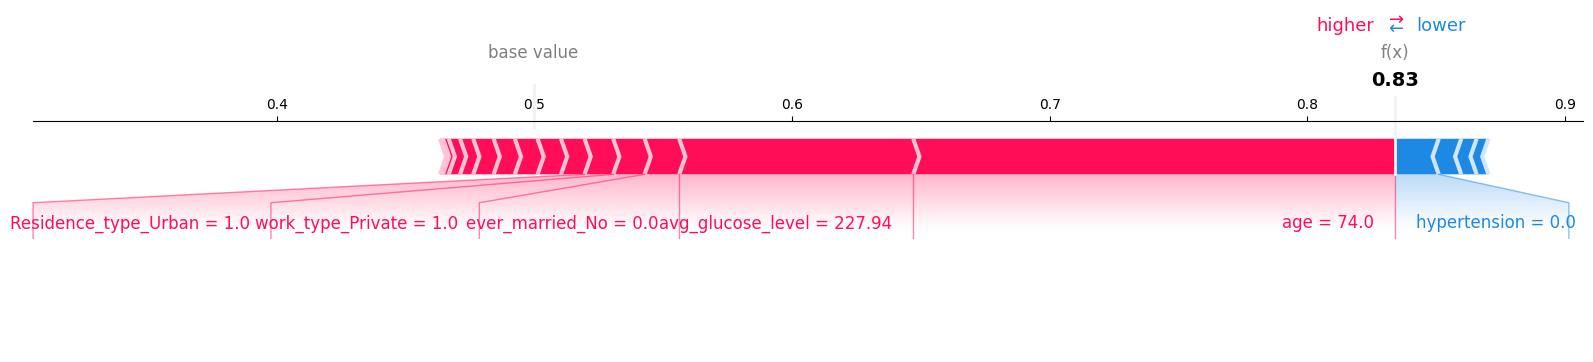

In [64]:
shap.force_plot(
    base_value_pos,
    shap_values_pos[high_risk_idx],
    X_test.iloc[high_risk_idx, :],
    matplotlib=True
)

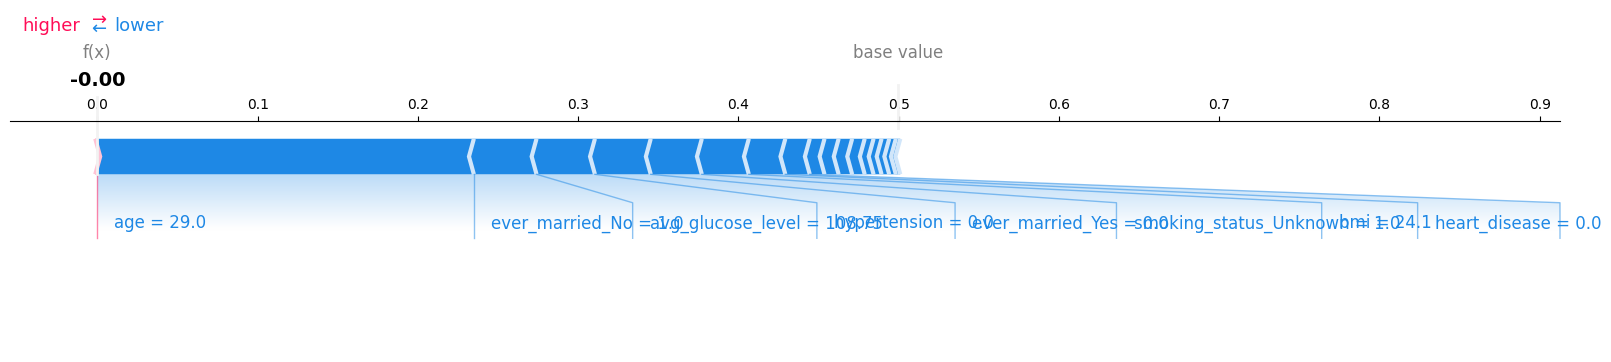

In [65]:
shap.force_plot(
    base_value_pos,
    shap_values_pos[low_risk_idx],
    X_test.iloc[low_risk_idx, :],
    matplotlib=True
)


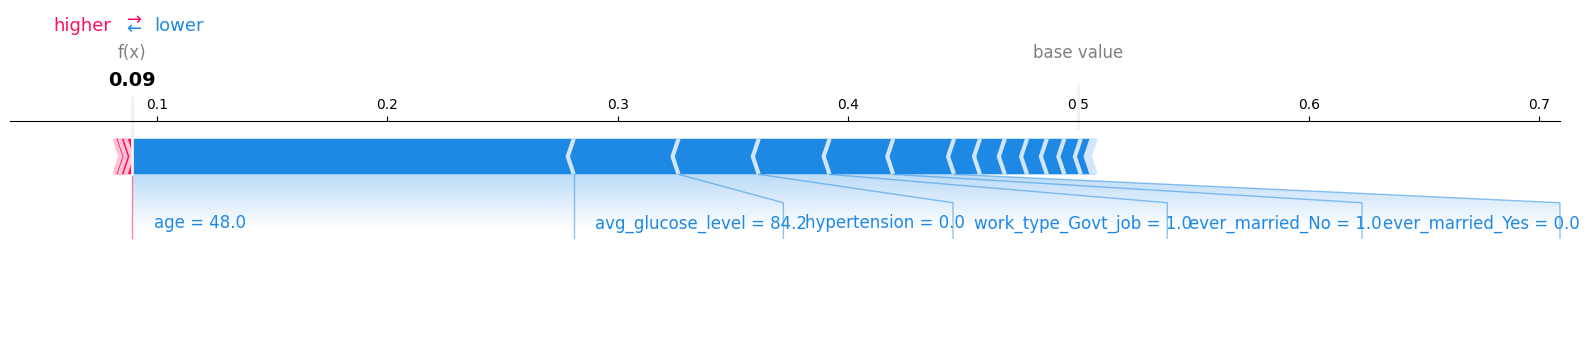

In [66]:
shap.force_plot(
    base_value_pos,
    shap_values_pos[stroke_idx],
    X_test.iloc[stroke_idx, :],
    matplotlib=True
)

# Task 4: Visualize global Explainer using Summary plot or other summary methods

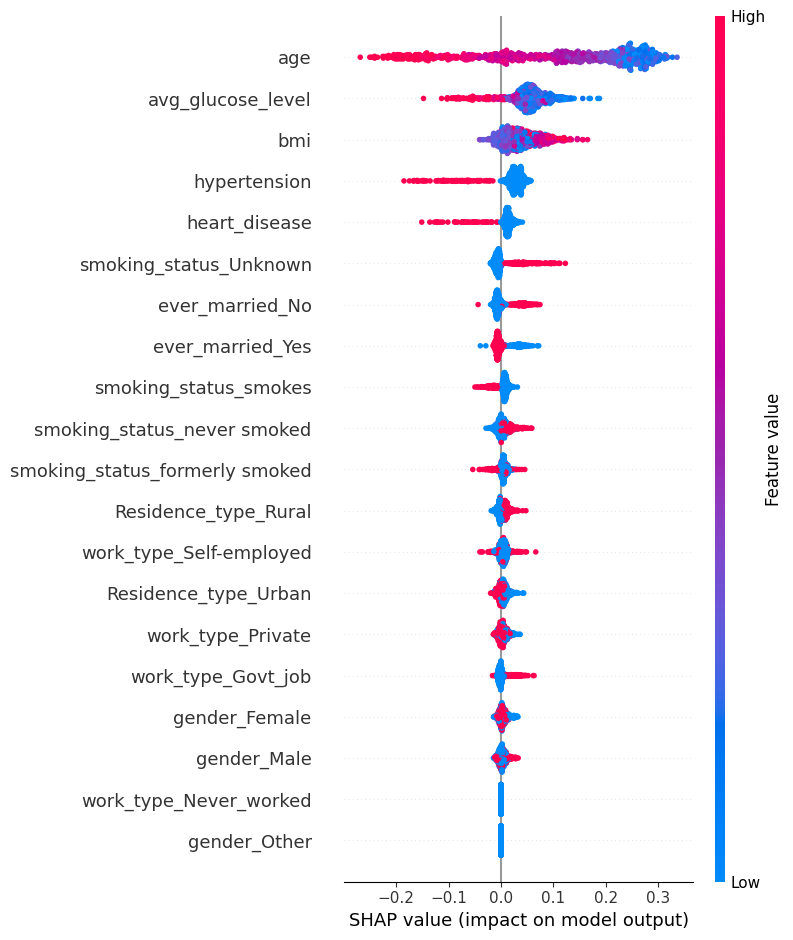

In [67]:
shap.summary_plot(shap_values_rf[:, :, 0], X_test)

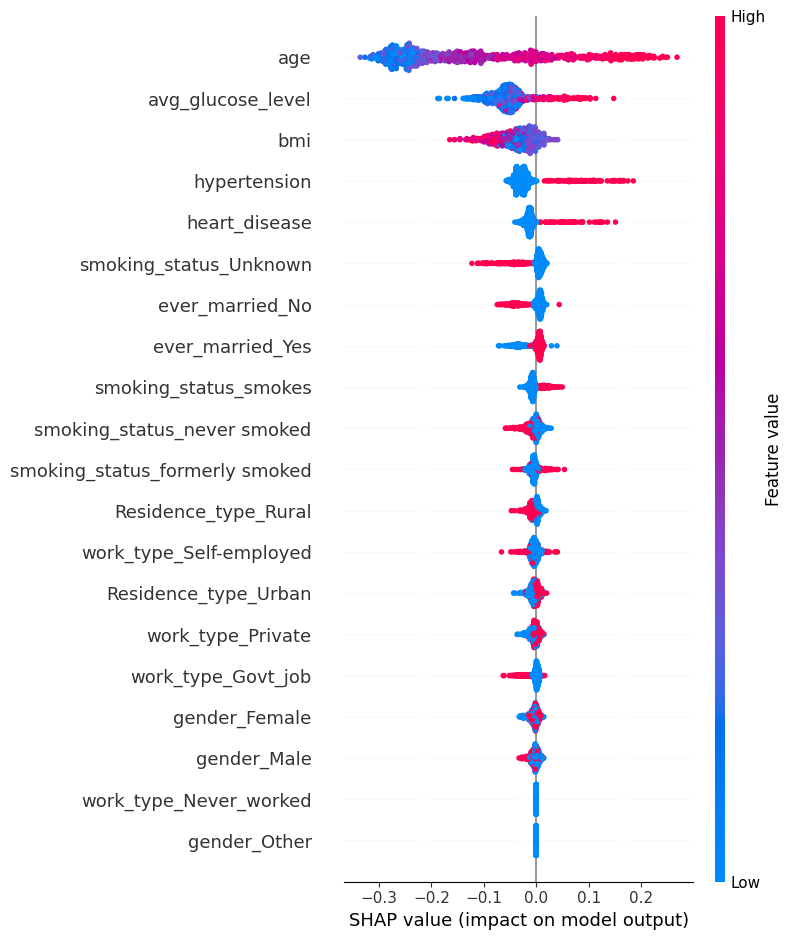

In [68]:
shap.summary_plot(shap_values_rf[:, :, 1], X_test)

# Create Deep SHAP or Kernel SHAP as an explainer and explain a chosen black box model different from Task 2

In [69]:
# Train an xgBoost model
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train_over, y_train_over)

# Predictions
y_pred_xgb = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("\nXGBoost Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_xgb):.4f}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_xgb):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))


XGBoost Performance:
Accuracy: 0.8859
F1 Score: 0.2051
ROC-AUC Score: 0.7848

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.92      0.94       770
           1       0.17      0.27      0.21        45

    accuracy                           0.89       815
   macro avg       0.56      0.59      0.57       815
weighted avg       0.91      0.89      0.90       815



In [70]:
# Use 100 samples from training data as background
background = shap.sample(X_train_over, 100)
f = lambda x: xgb_model.predict_proba(x)[:, 1]

In [71]:
#Use Kernel SHAP explainer
explainer_ker = shap.KernelExplainer(f, background)

In [72]:
shap_values_ker = explainer_ker.shap_values(X_test)

100%|██████████| 815/815 [00:31<00:00, 25.55it/s]


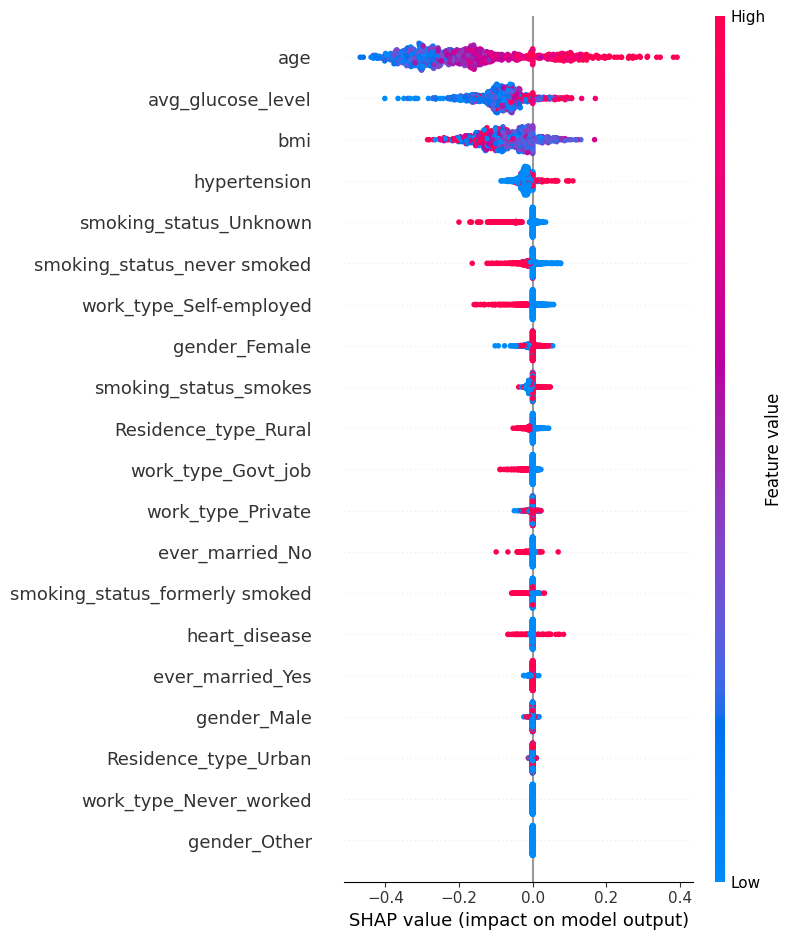

In [73]:
shap.summary_plot(shap_values_ker, X_test)

In [74]:
# Select interesting cases for explanation
high_risk_idx = np.argmax(y_pred_proba_xgb)   # highest probability of stroke
low_risk_idx = np.argmin(y_pred_proba_xgb)    # lowest probability of stroke

# Find a true stroke case if it exists
stroke_cases = np.where(y_test == 1)[0]
if len(stroke_cases) > 0:
    stroke_idx = stroke_cases[0]
else:
    stroke_idx = high_risk_idx

print(f"Highest risk index: {high_risk_idx} \n Lowest risk index: {low_risk_idx}\n Actual stroke index: {stroke_idx}")


Highest risk index: 205 
 Lowest risk index: 194
 Actual stroke index: 2


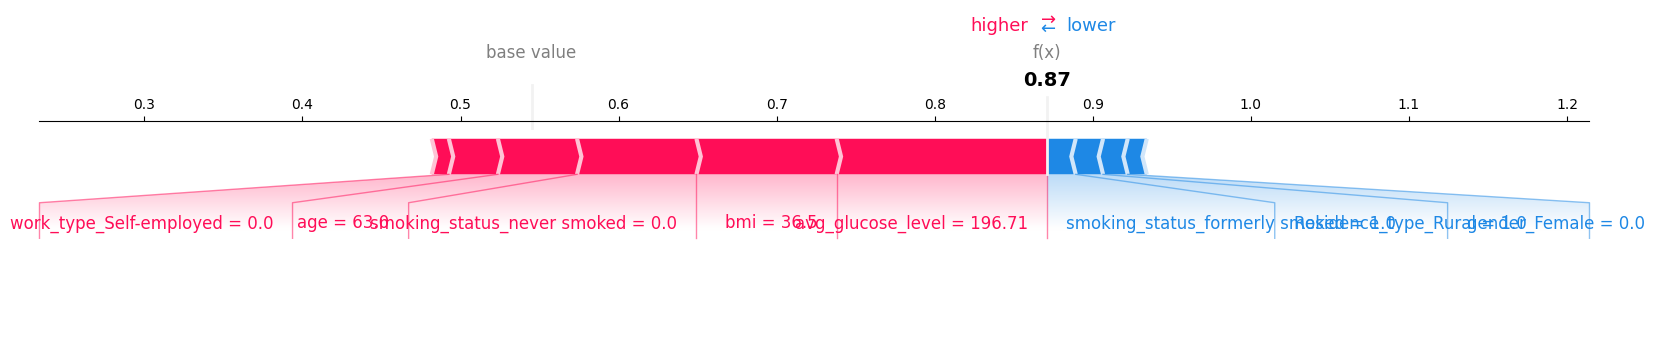

In [75]:
shap.force_plot(explainer_ker.expected_value, shap_values_ker[high_risk_idx], X_test.iloc[high_risk_idx],matplotlib=True)

100%|██████████| 1/1 [00:00<00:00, 25.04it/s]


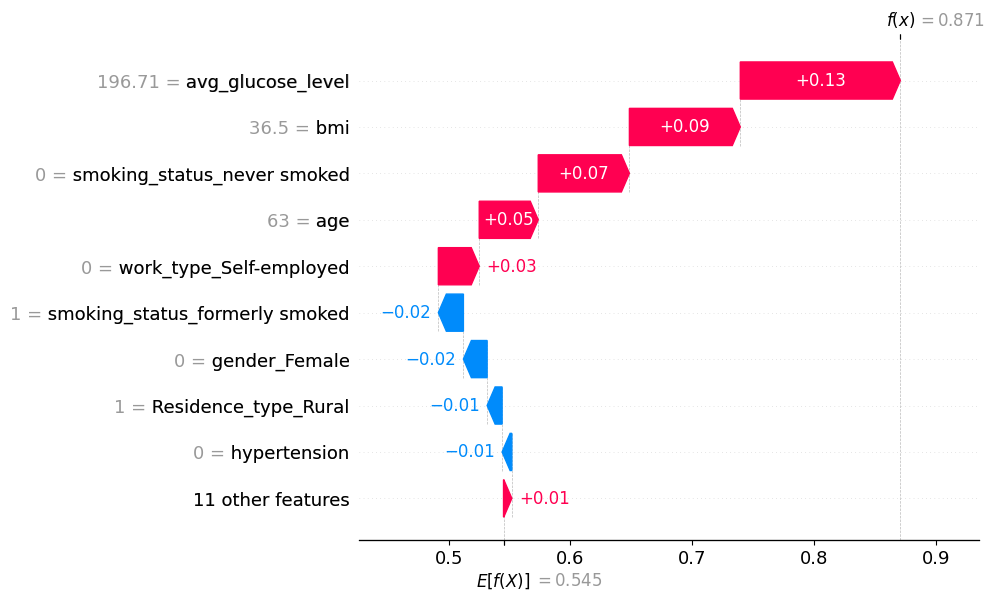

In [76]:
raw = explainer_ker(X_test.iloc[high_risk_idx:high_risk_idx+1])

shap_values = shap.Explanation(
    values      = raw.values[0],
    base_values = raw.base_values[0],
    data        = X_test.iloc[high_risk_idx].values,
    feature_names = X_test.columns
)

shap.plots.waterfall(shap_values)


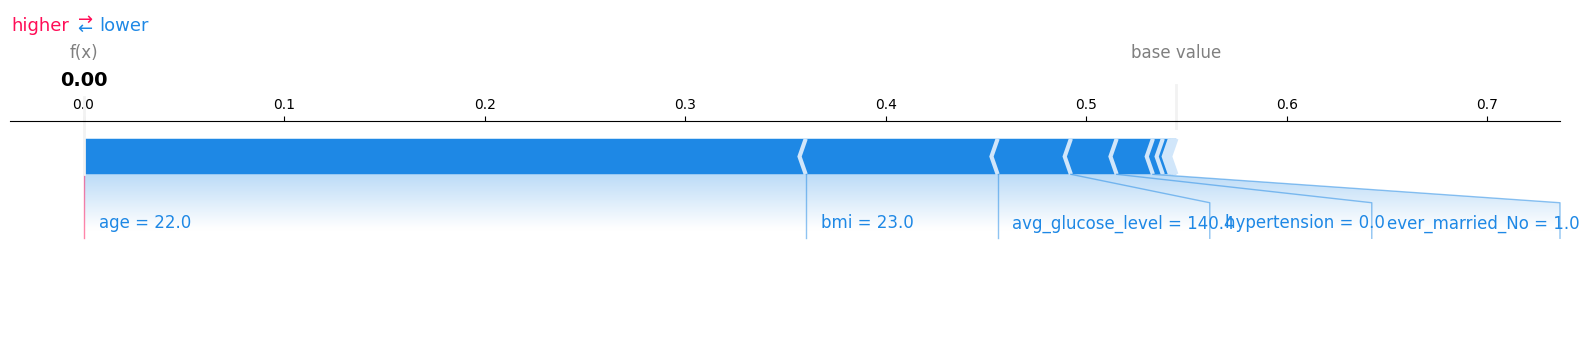

In [77]:
shap.force_plot(explainer_ker.expected_value, shap_values_ker[low_risk_idx], X_test.iloc[low_risk_idx],matplotlib=True)

100%|██████████| 1/1 [00:00<00:00, 25.17it/s]


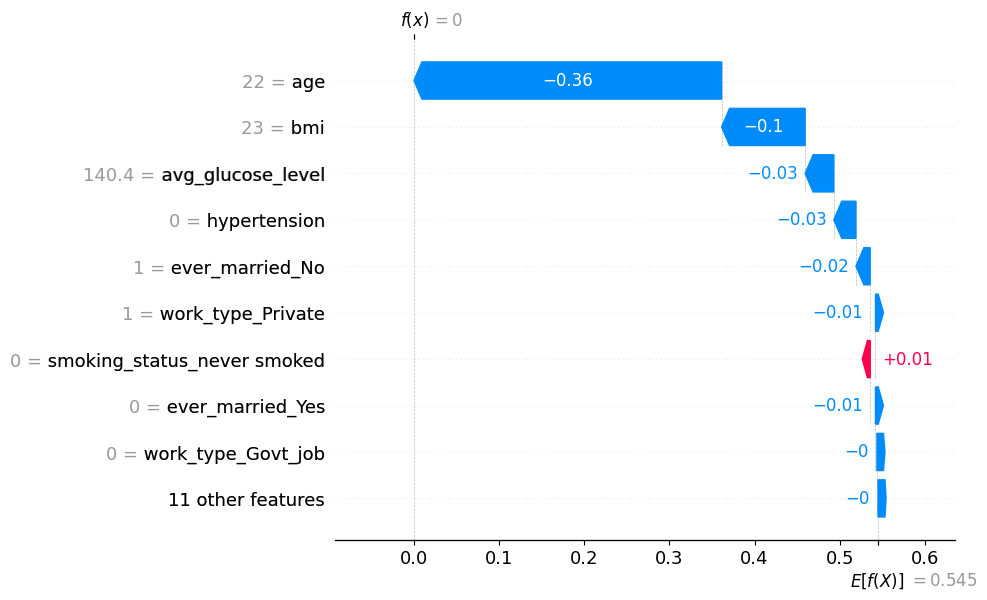

In [78]:
raw = explainer_ker(X_test.iloc[low_risk_idx:low_risk_idx+1])

shap_values = shap.Explanation(
    values      = raw.values[0],
    base_values = raw.base_values[0],
    data        = X_test.iloc[low_risk_idx].values,
    feature_names = X_test.columns
)

shap.plots.waterfall(shap_values)


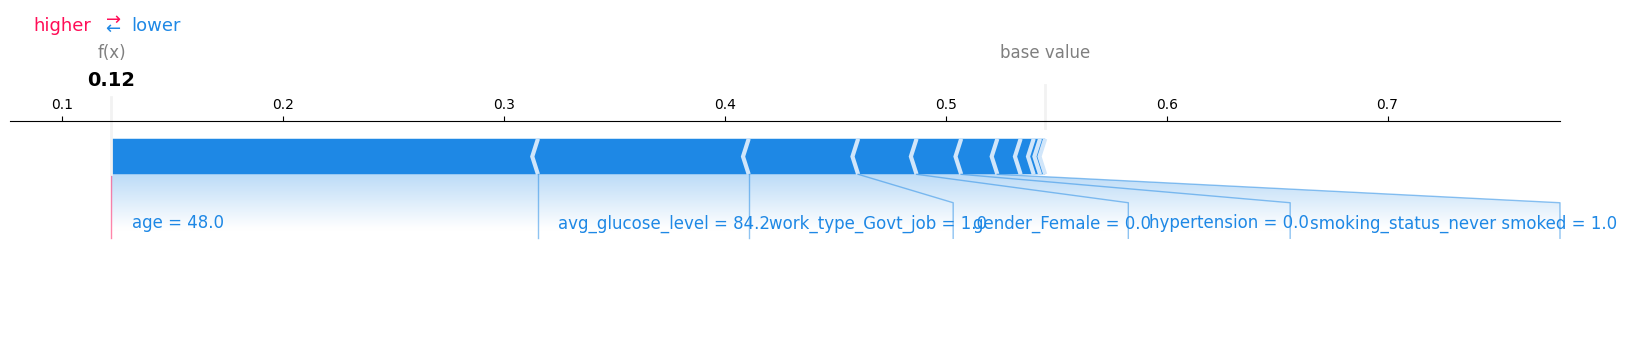

In [79]:
shap.force_plot(explainer_ker.expected_value, shap_values_ker[stroke_idx], X_test.iloc[stroke_idx],matplotlib=True)

100%|██████████| 1/1 [00:00<00:00, 24.16it/s]


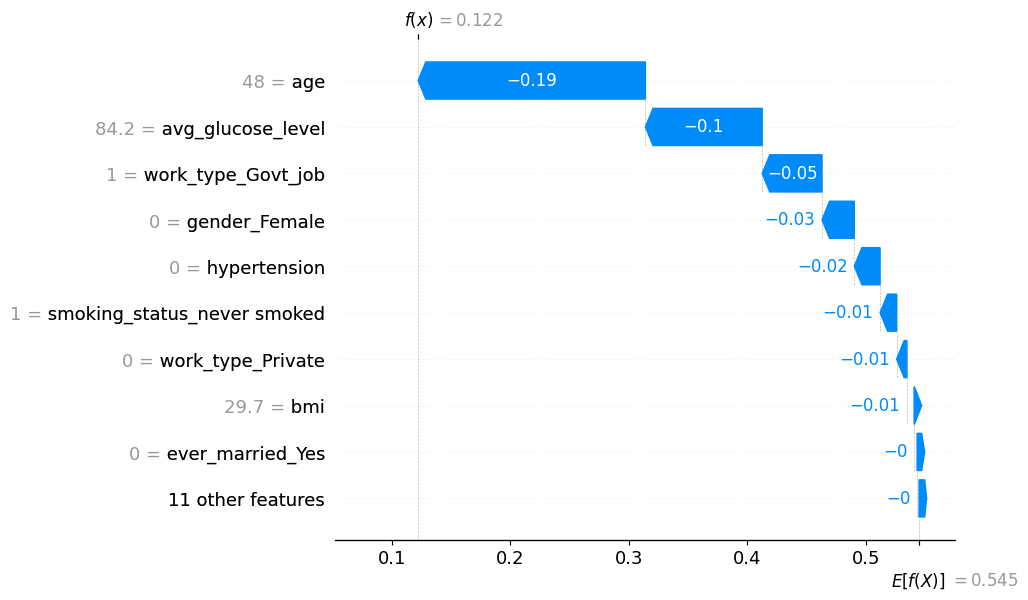

In [80]:
raw = explainer_ker(X_test.iloc[stroke_idx:stroke_idx+1])

shap_values = shap.Explanation(
    values      = raw.values[0],
    base_values = raw.base_values[0],
    data        = X_test.iloc[stroke_idx].values,
    feature_names = X_test.columns
)

shap.plots.waterfall(shap_values)


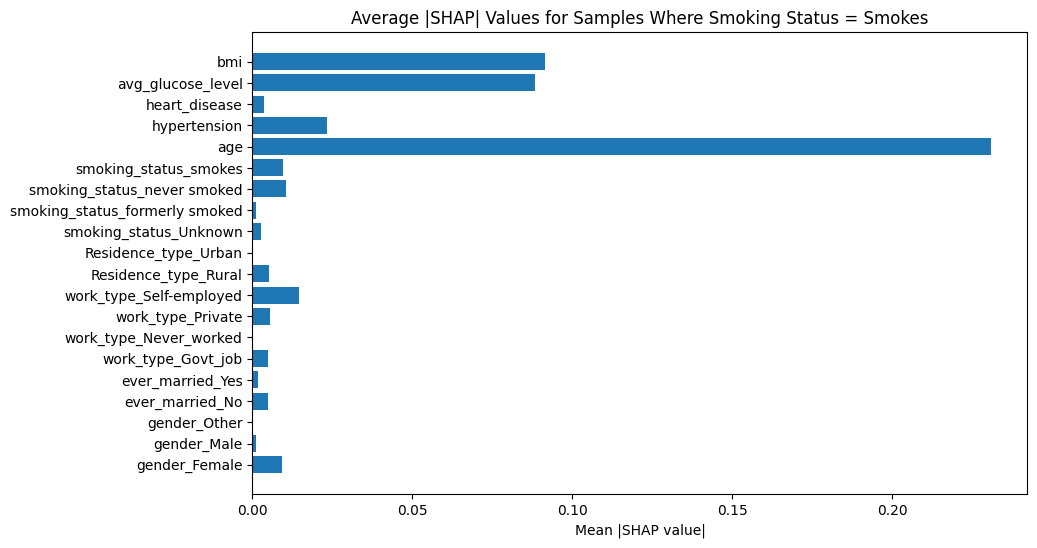

In [81]:
# Filter rows where smoking_status_smokes == 1
mask_smokes = X_test["smoking_status_smokes"] == 1

# SHAP values for this subgroup
shap_smokes = shap_values_ker[mask_smokes]

# Mean absolute SHAP values (importance)
mean_abs_smokes = np.mean(np.abs(shap_smokes), axis=0)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(X_test.columns, mean_abs_smokes)
plt.title("Average |SHAP| Values for Samples Where Smoking Status = Smokes")
plt.xlabel("Mean |SHAP value|")
plt.show()

In [82]:
# Column index
col = X_test.columns.get_loc("smoking_status_smokes")

# Mean SHAP value for the group
avg_shap_smokes = shap_values_ker[mask_smokes][:, col].mean()

print("Average SHAP value for smoking_status_smokes (for smokers):", avg_shap_smokes)


Average SHAP value for smoking_status_smokes (for smokers): 0.004269209186240712
